In [1]:
from functions_py import *
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
from scipy.stats import chisquare as chisquare
import pickle

sys.path.insert(0, '/home/oem/Software/Serial_Register_Events_Detection')
from ReconLib import *


In [14]:
def hist_RowColumn(data_array):
    Col=np.median(data_array, axis=0)
    #Col=data[10:640,0]#analisis de Registro vertical, Columnas V
    bins_Col=np.histogram_bin_edges(Col, bins='fd')
    Col_hist, bins_Col = np.histogram(Col,bins=bins_Col)
    u_Col, std_Col = norm.fit(Col)
    

    Row=np.median(data_array, axis=1)
    #Row=data[10,10:690] #analisis de Registro horizontal, Renglones H    
    bins_Row=np.histogram_bin_edges(Row, bins='fd')
    Row_hist, bins_Row = np.histogram(Row,bins=bins_Row) 
    u_Row, std_Row = norm.fit(Row)
    

    print('media on Row='+str(u_Row)+', stdDev on y='+str(std_Row))
    print('media on Col='+str(u_Col)+', stdDev on y='+str(std_Col))

    return Row, Col, bins_Row, bins_Col, Row_hist, Col_hist #Row_median, Col_median, bines Row, bines Col, Histogram Row, histogram Col

def line(x, m, b): #data, slope, y-intersection (ordenada al origen)
    return (m*x+b)

def secOrder(x,a,b,c):
    return a*x**2 + b*x + c 

def totTime(path):
    hdul=fits.open(path)# fits file to analyze
    header=hdul[0].header

    tStartList=str(header._cards[159]).split("'")[1].split('T')[1].split(':')
    tEndList=str(header._cards[160]).split("'")[1].split('T')[1].split(':')

    tStart=int(tStartList[0])*3600+int(tStartList[1])*60+int(tStartList[2])
    tEnd=int(tEndList[0])*3600+int(tEndList[1])*60+int(tEndList[2])

    dateStart=header._cards[159][1].split('T')[0]
    dateEnd=header._cards[160][1].split('T')[0]
    if (int(dateEnd.split('-')[-1])-int(dateStart.split('-')[-1])) >0:
        Ttot=tEnd+86400-tStart        # Total time 
    else:
        Ttot=tEnd-tStart        # Total time 

    NRow=int(str(header._cards[15]).split("'")[1])
    NCol=int(str(header._cards[16]).split("'")[1])
    NSamp=int(str(header._cards[17]).split("'")[1])


    deltaTperPix=Ttot/(NCol*NRow)
    deltaTperRow=Ttot/NRow

    expoTimes=[]
    
    for mCol in range(0,NCol):  #Fill Exposure Matrix
        expoTimes.append([])
        for nRow in range(0,NRow):
            expoTimes[mCol].append(deltaTperRow*mCol+deltaTperPix*nRow)


    ExpoMatrix=np.array(expoTimes)
    #NROW650_NCOL700
        
    
    return ExpoMatrix, Ttot, NRow, NCol, NSamp

def exposureFactor(path):
    ExpoMatrix,_,_,_,_=totTime(path)
    fig_all, axs_all = plt.subplots(nrows=1, ncols=2, figsize=(15, 5),constrained_layout=True)		# Create figures
    fig_all.suptitle('Exposure Factor', fontsize='large')
    popt, pcov = curve_fit(line, range(0, len(ExpoMatrix[0])),ExpoMatrix[0]) #ajustar valores de x y yRuido a la funcion "func"
    axs_all[0].set_title('Horizontal')
    axs_all[0].set_ylim([-4, 15])
    axs_all[0].set_ylabel('Exposure time [s]')
    axs_all[0].set_xlabel('Col')
    axs_all[1].set_xlabel('Row')
    axs_all[0].plot(range(0,len(ExpoMatrix[0])), line(range(0,len(ExpoMatrix[0])), popt[0], popt[1]),'r-', label='fit: m=%f [s/pix], b=%f' % tuple(popt))
    HEF=popt[0] #Horizontal exposure factor
    axs_all[0].legend()
    popt, pcov = curve_fit(line, range(0, len(ExpoMatrix[:,0])),ExpoMatrix[:,0])
    axs_all[1].set_title('Vertical')
    axs_all[1].plot(range(0,len(ExpoMatrix[:,0])), line(range(0,len(ExpoMatrix[:,0])), popt[0], popt[1]),'b-', label='fit by column: m=%f [s/pix], b=%f' % tuple(popt))
    VEF=popt[0] #Vertical Exposure Factor
    axs_all[1].legend()
    plt.show()
    return HEF, VEF

def sum_intensity(region, intensities):
    return np.sum(intensities[region])

plt.rcParams.update({
    "image.origin": "lower",
    "image.aspect": 1,
    #"text.usetex": True,
    "grid.alpha": .5,
    "axes.linewidth":2,
    "lines.linewidth" : 1,
    "font.size":    15.0,
    "xaxis.labellocation": 'right',  # alignment of the xaxis label: {left, right, center}
    "yaxis.labellocation": 'top',  # alignment of the yaxis label: {bottom, top, center}
    "xtick.top":           True ,  # draw ticks on the top side
    "xtick.major.size":    8    ,# major tick size in points
    "xtick.minor.size":    4      ,# minor tick size in points
    "xtick.direction":     'in',
    "xtick.minor.visible": True,
    "ytick.right":           True ,  # draw ticks on the top side
    "ytick.major.size":    8    ,# major tick size in points
    "ytick.minor.size":    4      ,# minor tick size in points
    "ytick.direction":     'in',
    "ytick.minor.visible": True,
    "ytick.major.width":   2   , # major tick width in points
    "ytick.minor.width":   1 ,
    "xtick.major.width":   2   , # major tick width in points
    "xtick.minor.width":   1 ,
    "legend.framealpha": 0 ,
    "legend.loc": 'best',

})

Filename: /home/oem/datosFits/Data_2023/01NOV2023/proc_skp_m-009_microchip_T_170__Vv82_NSAMP_324_NROW_400_NCOL_700_EXPOSURE_0_NBINROW_1_NBINCOL_1_img_80.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     165   (700, 400)   float32   
  1                1 ImageHDU       164   (700, 400)   float32   
  2                1 ImageHDU       164   (700, 400)   float32   
  3                1 ImageHDU       164   (700, 400)   float32   


None
----------------


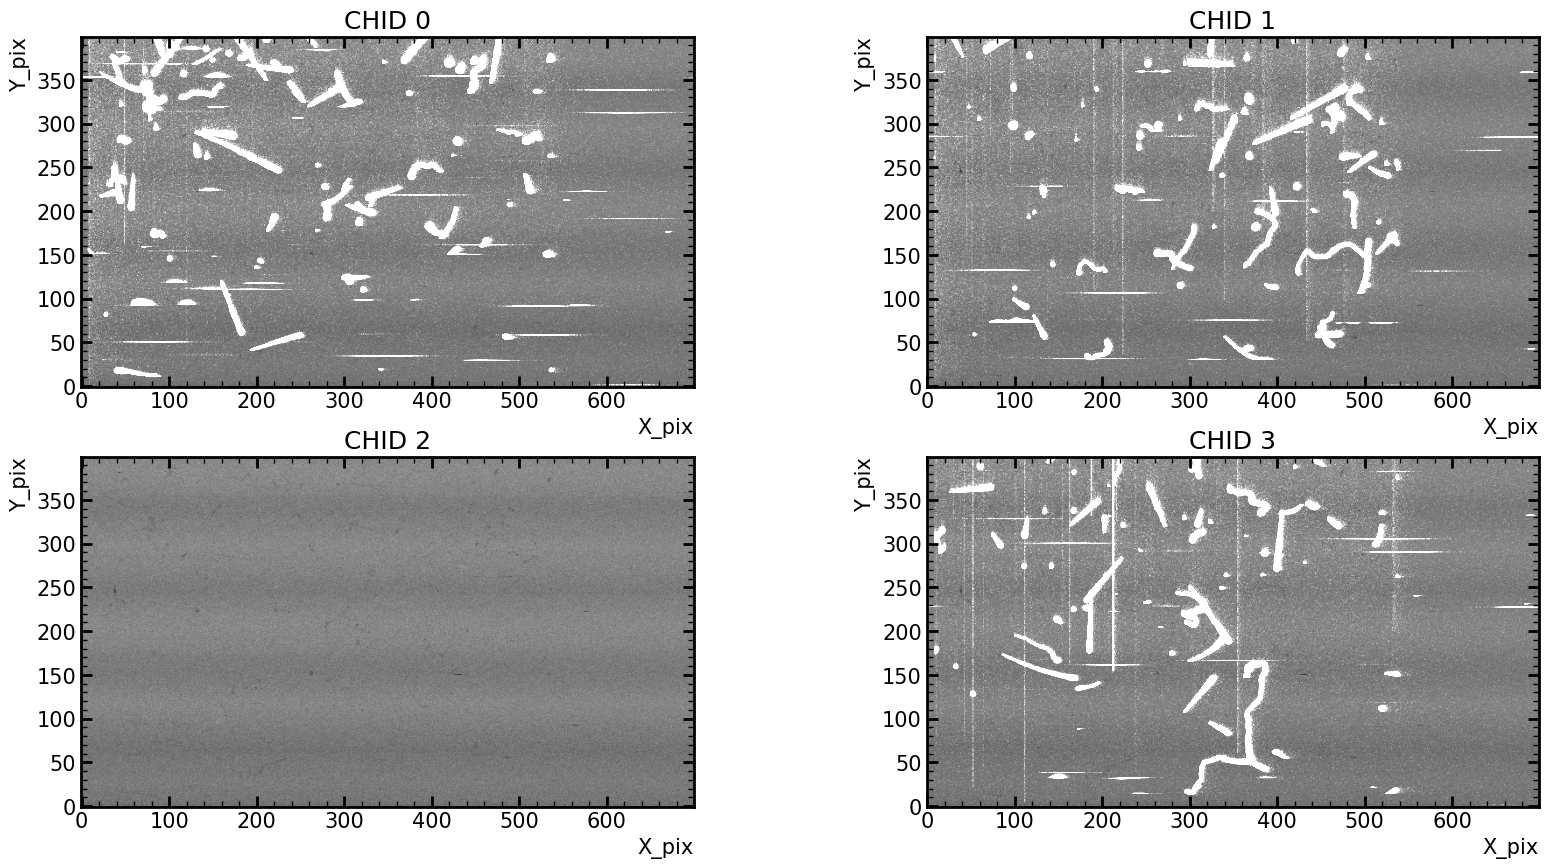

In [58]:
# ICN
# Datos desde 
path="/home/oem/datosFits/Data_2023/01NOV2023/proc_skp_m-009_microchip_T_170__Vv82_NSAMP_324_NROW_400_NCOL_700_EXPOSURE_0_NBINROW_1_NBINCOL_1_img_80.fits"

hdu_list = fits.open(path)
print(hdu_list.info())
print('----------------')
# hdu_list[0].header
plt.figure(figsize=(20,10))
for i in range(4):
    plt.subplot(2,2,i+1)
    plt.imshow(hdu_list[i].data[:,:]-np.median(hdu_list[i].data),vmin=-800,vmax=800,cmap='gray')
    plt.title('CHID '+str(i))
    plt.ylabel('Y_pix')
    plt.xlabel('X_pix')
plt.show()

In [109]:
hdu_list[0].header

SIMPLE  =                    T / file does conform to FITS standard             
BITPIX  =                  -32 / number of bits per data pixel                  
NAXIS   =                    2 / number of data axes                            
NAXIS1  =                  700 / length of data axis 1                          
NAXIS2  =                  400 / length of data axis 2                          
EXTEND  =                    T / FITS dataset may contain extensions            
COMMENT   FITS (Flexible Image Transport System) format is defined in 'Astronomy
COMMENT   and Astrophysics', volume 376, page 359; bibcode: 2001A&A...376..359H 
CCDNCOL = '1058    '           / Smart sequencer variable                       
CCDNPRES= '7       '           / Smart sequencer variable                       
CCDNROW = '1278    '           / Smart sequencer variable                       
HIERARCH CLEARNCOL = '4000    ' / Smart sequencer variable                      
EXPOSURE= '0       '        

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


median= 14462.377


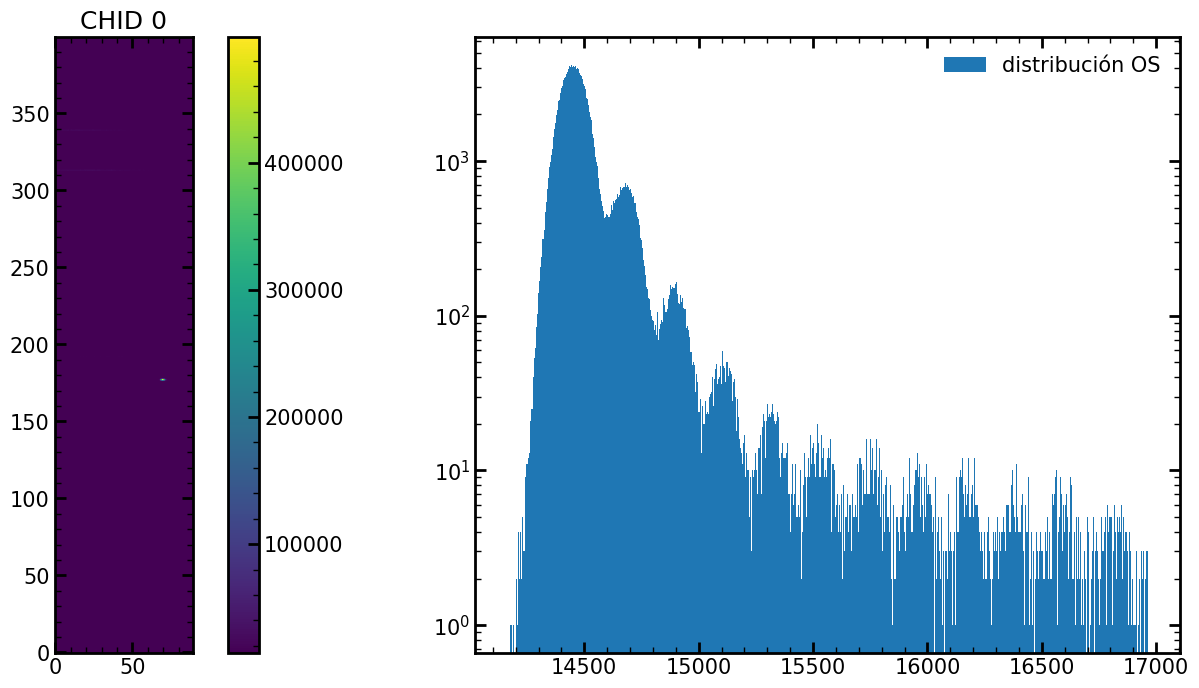

In [68]:
plt.figure(figsize=(20,8))
ext=0
plt.subplot(1,2,1)
plt.imshow(hdu_list[ext].data[:,600:690])
plt.colorbar() 
plt.title("CHID 0")
plt.legend()

plt.subplot(1,2,2)
median=np.median(hdu_list[ext].data[:,500:])
histogram=plt.hist(hdu_list[ext].data.flatten(), bins=1000, log=True, label=("distribución OS"), range=(median-300, median+2500))
print('median=',median)

plt.legend()

(0.1, 733.9755541230469)

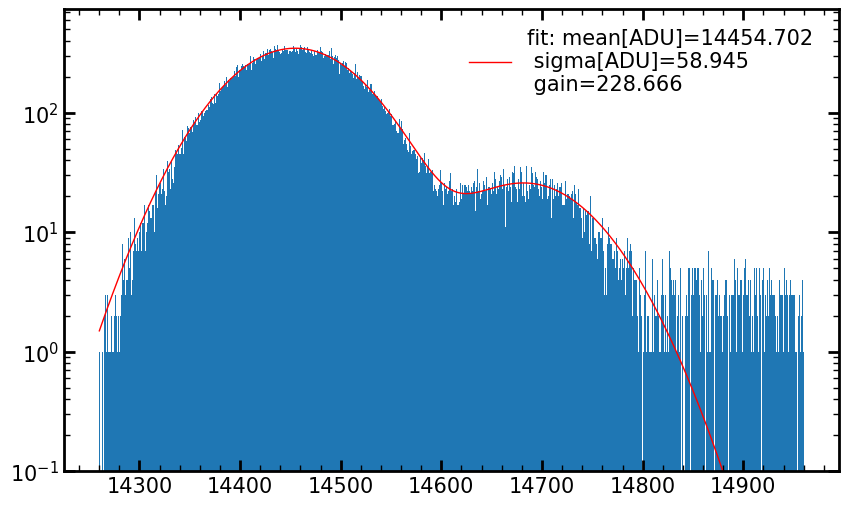

In [108]:
Data=hdu_list[ext].data[:,500:].flatten()
median=np.median(hdu_list[ext].data[:,600:690])
fig = plt.figure(figsize=(10,6))
hist_OS, bins_OS, patches_OS=plt.hist(Data, bins=1000, range=(median-200, median+500), log=True)#, log=True)


bins_Os=(bins_OS[1:]+bins_OS[:-1])/2
bins_Os

popt_OS_1,_=curve_fit(gaussian2,bins_Os, hist_OS, p0=(median,80,200,100,10))


plt.subplot(1,1,1)
Ajuste=plt.plot(bins_Os, gaussian2(bins_Os, *popt_OS_1), color='red', label='fit: mean[ADU]=%5.3f \n sigma[ADU]=%5.3f \n gain=%5.3f ' % (popt_OS_1[0],popt_OS_1[1],popt_OS_1[2]))
plt.legend()
plt.ylim(bottom=.1)     

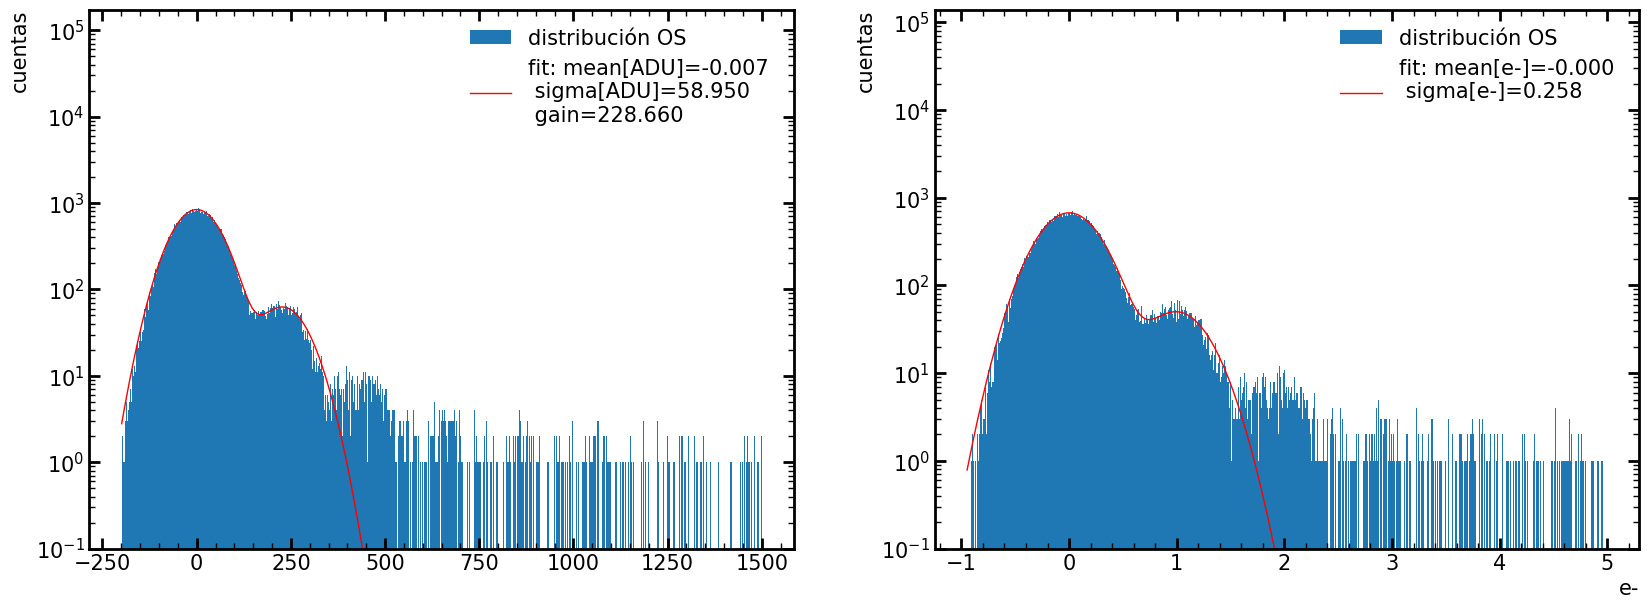

In [ ]:
median_fit=popt_OS_1[0]
#gaussian2(x,m,s,g,a1,a2): #data, popt (mean, sigma, gain, height1, heigth2)
Data_AA=hdu_list[ext].data[:,:550].flatten()
median_AA=np.median(hdu_list[ext].data[:,:550].flatten())
Data=hdu_list[ext].data[:,500:].flatten()
median=np.median(hdu_list[ext].data[:,500:])
plt.figure(figsize=(20,7))

# Plot Distribucion y ajuste de la region AA

plt.subplot(1,2,1)
hist_OS,bins_OS,_=plt.hist(Data-median_fit, bins=1000, range=(-200, 1500), log=True, label=("distribución OS"))

bins=(bins_OS[1:]+bins_OS[:-1])/2
popt_OS,_=curve_fit(gaussian2,bins, hist_OS, p0=[0,80,200,1e3,1e2])

plt.plot(bins, gaussian2(bins,*popt_OS), color='red'  , label='fit: mean[ADU]=%5.3f \n sigma[ADU]=%5.3f \n gain=%5.3f ' % (popt_OS[0],popt_OS[1],popt_OS[2]))
plt.ylim(bottom=.1)
plt.ylabel('cuentas')
plt.legend()

# Plot Distribucion y ajuste de la region OS

plt.subplot(1,2,2)
hist_OS,bins_OS,_=plt.hist((Data-median_fit)/popt_OS[2], bins=1000, range=(-.95, 5), log=True, label=("distribución OS"))

bins_OS=(bins_OS[1:]+bins_OS[:-1])/2
popt_OS,_=curve_fit(gaussian2,bins_OS, hist_OS, p0=[0,.25,1,1e3,1e2])

plt.plot(bins_OS, gaussian2(bins_OS,*popt_OS), color='red', label='fit: mean[e-]=%5.3f \n sigma[e-]=%5.3f \n' % (popt_OS[0],popt_OS[1]))
plt.ylim(bottom=.1)
plt.ylabel('cuentas')
plt.legend()
plt.xlabel('e-')
plt.legend()

In [92]:
bins

array([-1.99149994e+02, -1.97450012e+02, -1.95750000e+02, -1.94049988e+02,
       -1.92350006e+02, -1.90649994e+02, -1.88950012e+02, -1.87250000e+02,
       -1.85549988e+02, -1.83850006e+02, -1.82149994e+02, -1.80450012e+02,
       -1.78750000e+02, -1.77049988e+02, -1.75350006e+02, -1.73649994e+02,
       -1.71950012e+02, -1.70250000e+02, -1.68549988e+02, -1.66850006e+02,
       -1.65149994e+02, -1.63450012e+02, -1.61750000e+02, -1.60049988e+02,
       -1.58350006e+02, -1.56649994e+02, -1.54950012e+02, -1.53250000e+02,
       -1.51549988e+02, -1.49850006e+02, -1.48149994e+02, -1.46450012e+02,
       -1.44750000e+02, -1.43049988e+02, -1.41350006e+02, -1.39649994e+02,
       -1.37950012e+02, -1.36250000e+02, -1.34549988e+02, -1.32850006e+02,
       -1.31149994e+02, -1.29450012e+02, -1.27750000e+02, -1.26050003e+02,
       -1.24349998e+02, -1.22650002e+02, -1.20949997e+02, -1.19250000e+02,
       -1.17550003e+02, -1.15849998e+02, -1.14150002e+02, -1.12449997e+02,
       -1.10750000e+02, -

In [93]:
len(bins)

1000

In [105]:
label=ndimage.label(hdu_list[0].data[:,:550]>8000,structure=[[1,1,1],[1,1,1],[1,1,1]])[0]
#Event Mask
event_mask=np.invert(label==0)

#Serial Register Event mask
serial_mask=np.ma.make_mask(serialRegisterEvents_n3[:,:550])

#Combined Masks
main_mask=np.ma.mask_or(event_mask, serial_mask)

Plot2Images(hdu_list[0].data[:,:550], main_mask, MinRange=hdu_list[0].data[:,:550].min(), MaxRange=800000)

NameError: name 'serialRegisterEvents_n3' is not defined